# Unsupervised Clustering of Student Stress Patterns

This project explores patterns in student stress-related survey data using K-Means, Agglomerative Clustering, Bisecting K-Means, Gaussian Mixture Models, and DBSCAN. PCA, t-SNE, and SNE are used to examine the data in lower-dimensional spaces.

The dataset contains 1,100 records, 20 predictor variables, and the `stress_level` field. The target is excluded from preprocessing, dimensionality reduction, and model fitting; it is used only for post-clustering comparison.

**Setup:** Keep `StressLevelDataset.csv` beside this notebook, or place it in a `data/` or `dataset/` subfolder. Run the cells in order.

## Analysis steps

1. Inspect the dataset and examine feature distributions.
2. Prepare and standardize the predictor variables.
3. Fit and compare clustering algorithms.
4. Examine the data with PCA, t-SNE, and SNE.
5. Review cluster profiles and compare clusters with the held-out label.
6. Save figures, tables, and cluster assignments.


## 0. Environment and imports

In [ ]:
import sys
import json
import math
import warnings
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import minimize
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from sklearn.metrics import pairwise_distances
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture

try:
    from sklearn.cluster import BisectingKMeans
    HAS_BISECTING_KMEANS = True
except ImportError:
    BisectingKMeans = None
    HAS_BISECTING_KMEANS = False

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
TARGET = 'stress_level'

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

OUTPUT_DIR = Path('outputs_student_stress')
FIG_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
MODEL_DIR = OUTPUT_DIR / 'models'
for folder in (OUTPUT_DIR, FIG_DIR, TABLE_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('Output folder:', OUTPUT_DIR.resolve())
print('BisectingKMeans available:', HAS_BISECTING_KMEANS)

## 1. Load the dataset

In [ ]:
possible_paths = [
    Path('StressLevelDataset.csv'),
    Path('data') / 'StressLevelDataset.csv',
    Path('dataset') / 'StressLevelDataset.csv',
]
DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    matches = [
        path for path in Path.cwd().rglob('StressLevelDataset.csv')
        if not any(part.startswith('.') for part in path.parts)
        and 'site-packages' not in path.parts
    ]
    if matches:
        DATA_PATH = matches[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        'Could not find StressLevelDataset.csv. Place it beside this notebook '
        'or inside a data/ or dataset/ folder, then rerun this cell.'
    )

df = pd.read_csv(DATA_PATH)
print('Loaded:', DATA_PATH.resolve())
print('Dataset shape:', df.shape)
display(df.head())

## 2. Dataset inspection and quality checks

In [ ]:
print('Dataset information:')
df.info()

print('\nDescriptive statistics:')
display(df.describe(include='all').T)

print('\nData types:')
display(df.dtypes.astype(str).rename('data_type').to_frame())

print('\nMissing values by column:')
display(df.isna().sum().rename('missing_count').to_frame())

print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Target column exists:', TARGET in df.columns)

if TARGET not in df.columns:
    raise ValueError(f"Expected target column '{TARGET}' was not found. Check the CSV columns.")

if df.shape[0] < 10:
    raise ValueError('The dataset appears too small for the planned clustering experiments.')

feature_summary = pd.DataFrame({
    'data_type': df.dtypes.astype(str),
    'unique_values': df.nunique(dropna=True),
    'minimum': df.min(numeric_only=True),
    'maximum': df.max(numeric_only=True),
})
display(feature_summary)
feature_summary.to_csv(TABLE_DIR / 'feature_summary.csv')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load             

,count,mean,std,min,25%,50%,75%,max
anxiety_level,1100.0,11.063636,6.117558,0.0,6.0,11.0,16.0,21.0
self_esteem,1100.0,17.777273,8.944599,0.0,11.0,19.0,26.0,30.0
mental_health_history,1100.0,0.492727,0.500175,0.0,0.0,0.0,1.0,1.0
depression,1100.0,12.555455,7.727008,0.0,6.0,12.0,19.0,27.0
headache,1100.0,2.508182,1.409356,0.0,1.0,3.0,3.0,5.0
blood_pressure,1100.0,2.181818,0.833575,1.0,1.0,2.0,3.0,3.0
sleep_quality,1100.0,2.660000,1.548383,0.0,1.0,2.5,4.0,5.0
breathing_problem,1100.0,2.753636,1.400713,0.0,2.0,3.0,4.0,5.0
noise_level,1100.0,2.649091,1.328127,0.0,2.0,3.0,3.0,5.0
living_conditions,1100.0,2.518182,1.119208,0.0,2.0,2.0,3.0,5.0



Data types:


,data_type
anxiety_level,int64
self_esteem,int64
mental_health_history,int64
depression,int64
headache,int64
blood_pressure,int64
sleep_quality,int64
breathing_problem,int64
noise_level,int64
living_conditions,int64



Missing values by column:


,missing_count
anxiety_level,0
self_esteem,0
mental_health_history,0
depression,0
headache,0
blood_pressure,0
sleep_quality,0
breathing_problem,0
noise_level,0
living_conditions,0


Exact duplicate rows: 0
Target column exists: True


,data_type,unique_values,minimum,maximum
anxiety_level,int64,22,0,21
self_esteem,int64,31,0,30
mental_health_history,int64,2,0,1
depression,int64,28,0,27
headache,int64,6,0,5
blood_pressure,int64,3,1,3
sleep_quality,int64,6,0,5
breathing_problem,int64,6,0,5
noise_level,int64,6,0,5
living_conditions,int64,6,0,5


## 3. Exploratory data analysis (EDA)

Histograms, a Spearman correlation heatmap, and boxplots are used to examine feature distributions and relationships. Extreme values are reviewed but are not removed automatically, since they may represent valid survey responses.


Predictor shape: (1100, 20)
Held-out target shape: (1100,)

Target value counts (descriptive only):


,count
stress_level,
0,373
1,358
2,369


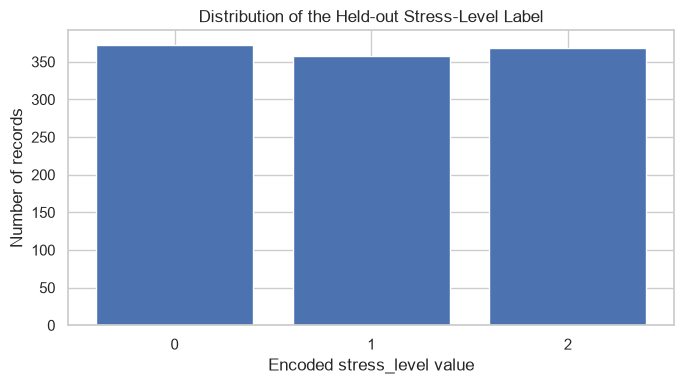

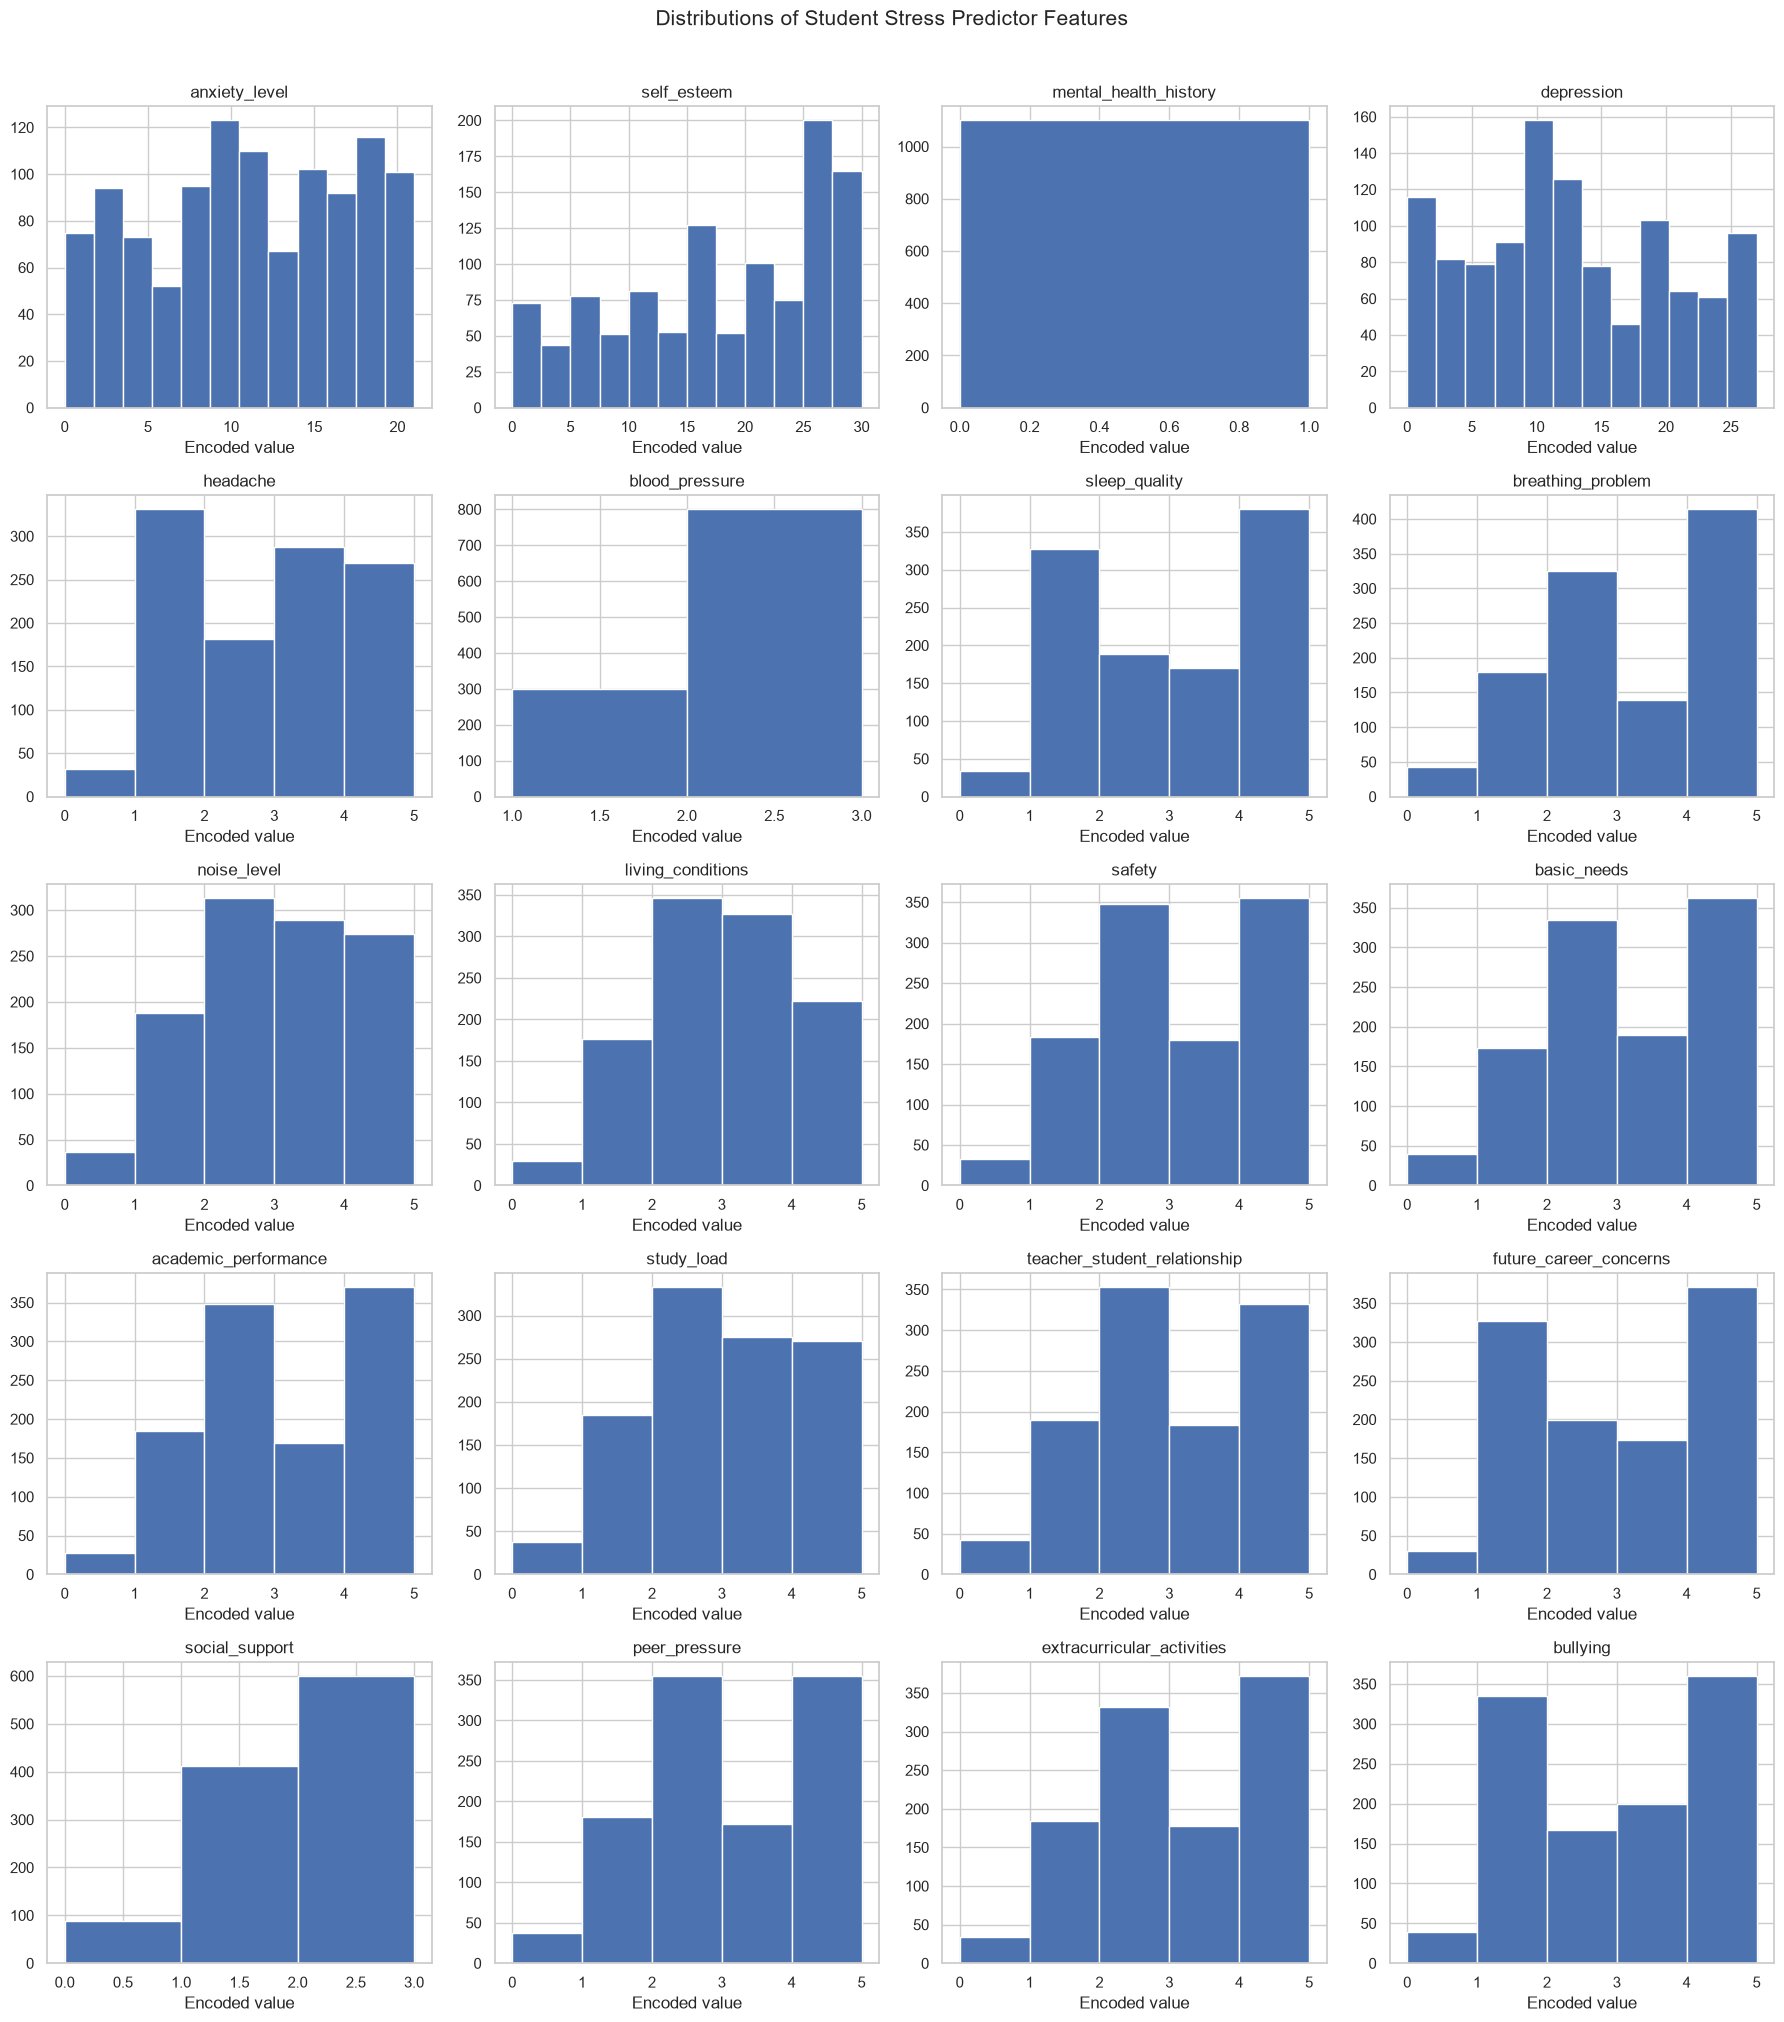

No missing values found in predictor features.


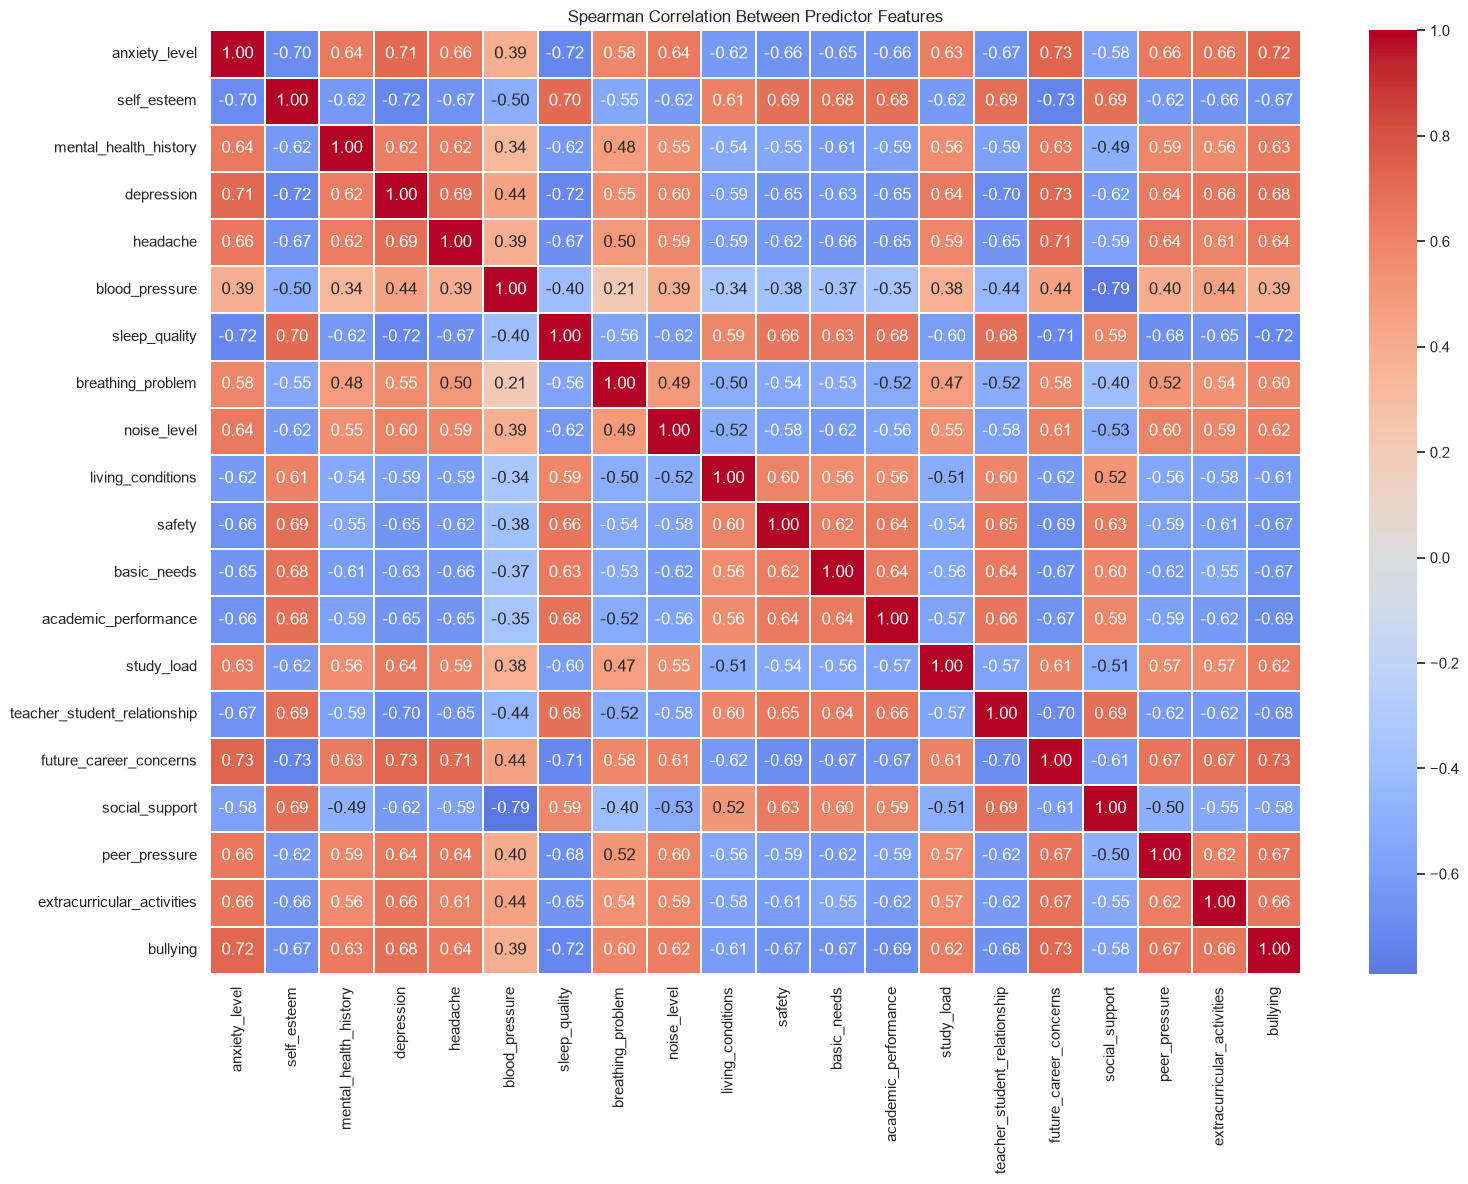

C:\Users\samru\AppData\Local\Temp\ipykernel_26032\2219733544.py:67: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(box_data, vert=False)


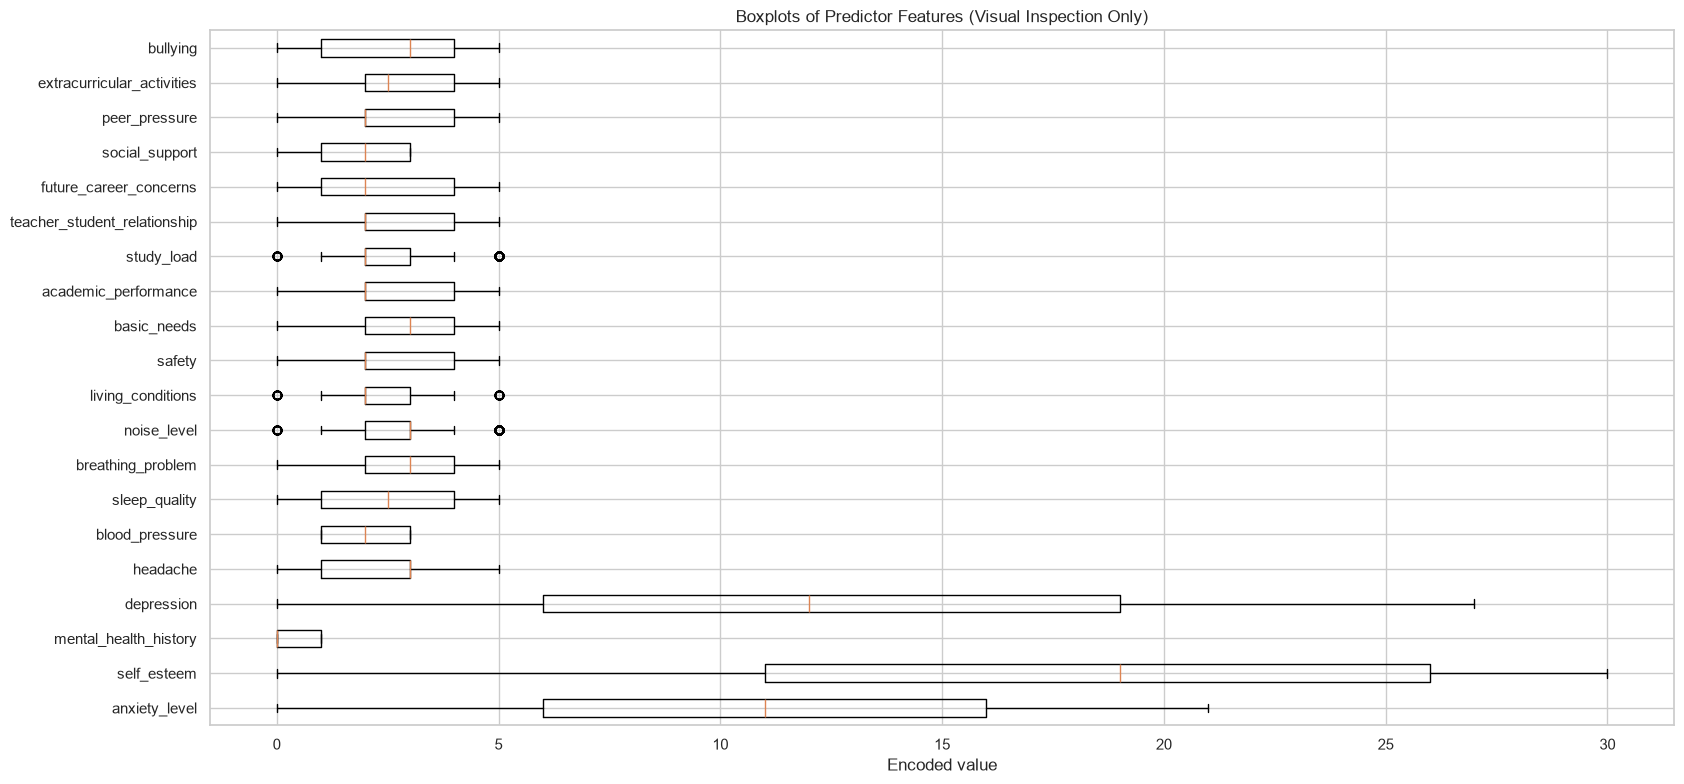

In [ ]:

X_raw = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

X_numeric = X_raw.apply(pd.to_numeric, errors='coerce')
non_numeric_after_conversion = X_numeric.columns[X_numeric.isna().all()].tolist()
if non_numeric_after_conversion:
    raise ValueError(
        'These predictor columns could not be converted to numeric values: '
        + ', '.join(non_numeric_after_conversion)
    )

print('Predictor shape:', X_numeric.shape)
print('Held-out target shape:', y.shape)
print('\nTarget value counts (descriptive only):')
display(y.value_counts(dropna=False).sort_index().rename('count').to_frame())

fig, ax = plt.subplots(figsize=(7, 4))
target_counts = y.value_counts(dropna=False).sort_index()
ax.bar(target_counts.index.astype(str), target_counts.values)
ax.set_title('Distribution of the Held-out Stress-Level Label')
ax.set_xlabel('Encoded stress_level value')
ax.set_ylabel('Number of records')
fig.tight_layout()
fig.savefig(FIG_DIR / 'target_distribution_posthoc_only.png', dpi=160, bbox_inches='tight')
plt.show()

n_cols = 4
n_rows = math.ceil(X_numeric.shape[1] / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = np.array(axes).reshape(-1)
for idx, column in enumerate(X_numeric.columns):
    axes[idx].hist(X_numeric[column].dropna(), bins='auto')
    axes[idx].set_title(column)
    axes[idx].set_xlabel('Encoded value')
for ax in axes[len(X_numeric.columns):]:
    ax.set_visible(False)
fig.suptitle('Distributions of Student Stress Predictor Features', y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIG_DIR / 'feature_distributions.png', dpi=160, bbox_inches='tight')
plt.show()

missing_total = int(X_numeric.isna().sum().sum())
if missing_total:
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.heatmap(X_numeric.isna(), cbar=False, cmap='magma', ax=ax)
    ax.set_title('Missing-Value Pattern in Predictor Features')
    fig.tight_layout()
    fig.savefig(FIG_DIR / 'missing_value_pattern.png', dpi=160, bbox_inches='tight')
    plt.show()
else:
    print('No missing values found in predictor features.')

correlation = X_numeric.corr(method='spearman')
fig, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(correlation, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            linewidths=0.25, ax=ax)
ax.set_title('Spearman Correlation Between Predictor Features')
fig.tight_layout()
fig.savefig(FIG_DIR / 'spearman_correlation_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(17, 8))
box_data = [X_numeric[column].dropna().to_numpy() for column in X_numeric.columns]
ax.boxplot(box_data, vert=False)
ax.set_yticks(range(1, len(X_numeric.columns) + 1), labels=X_numeric.columns)
ax.set_title('Boxplots of Predictor Features (Visual Inspection Only)')
ax.set_xlabel('Encoded value')
fig.tight_layout()
fig.savefig(FIG_DIR / 'feature_boxplots.png', dpi=160, bbox_inches='tight')
plt.show()

## 4. Preprocessing

The 20 predictor variables are stored as integer-coded scores or ratings. For the baseline distance-based analysis, their numeric ordering is retained. Missing values are median-imputed, and features are standardized so that variables with wider ranges do not dominate distance calculations.

The `stress_level` field is kept separate and is not used for imputation, scaling, PCA, SNE, t-SNE, or clustering.


In [ ]:
feature_names = X_numeric.columns.tolist()

imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X_numeric)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

X_scaled_df = pd.DataFrame(X_scaled, columns=feature_names, index=df.index)
print('Processed feature matrix shape:', X_scaled.shape)
print('Any non-finite values after preprocessing:', not np.isfinite(X_scaled).all())
display(X_scaled_df.head())

preprocessing_summary = pd.DataFrame({
    'feature': feature_names,
    'imputed_missing_count': X_numeric.isna().sum().values,
    'mean_after_scaling': X_scaled.mean(axis=0),
    'std_after_scaling': X_scaled.std(axis=0),
})
display(preprocessing_summary)
preprocessing_summary.to_csv(TABLE_DIR / 'preprocessing_summary.csv', index=False)

Processed feature matrix shape: (1100, 20)
Any non-finite values after preprocessing: False


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying
0,0.480208,0.248612,-0.985559,-0.201393,-0.360741,-1.418416,-0.426445,0.890211,-0.488949,0.430695,0.186924,-0.539196,0.160736,-0.472800,0.254213,0.229550,0.112839,0.186334,0.164249,-0.403377
1,0.643746,-1.093590,1.014653,0.316508,1.768859,0.981981,-1.072574,0.890211,0.264334,-1.357096,-0.524551,-0.539196,-1.253741,1.047901,-1.190927,1.537869,-0.841952,0.888277,1.575763,1.557071
2,0.153131,0.024912,1.014653,0.187033,-0.360741,-1.418416,-0.426445,-0.538282,-0.488949,-0.463200,0.186924,-0.539196,-0.546502,0.287551,0.254213,-0.424609,0.112839,0.186334,-0.541508,-0.403377
3,0.807284,-0.646189,1.014653,0.316508,1.058992,0.981981,-1.072574,0.175964,1.017616,-0.463200,-0.524551,-0.539196,-0.546502,1.047901,-1.190927,0.883709,-0.841952,0.888277,0.870006,1.557071
4,0.807284,1.143414,-0.985559,-0.719293,-0.360741,0.981981,1.511942,-1.252529,0.264334,-0.463200,0.898398,0.158587,0.867974,0.287551,-1.190927,-0.424609,-0.841952,1.590220,-1.953023,1.557071


,feature,imputed_missing_count,mean_after_scaling,std_after_scaling
0,anxiety_level,0,-1.356491e-16,1.0
1,self_esteem,0,-3.229740e-18,1.0
2,mental_health_history,0,1.098112e-16,1.0
3,depression,0,8.074349e-17,1.0
4,headache,0,-6.943940e-17,1.0
5,blood_pressure,0,2.293115e-16,1.0
6,sleep_quality,0,-9.689219e-17,1.0
7,breathing_problem,0,1.550275e-16,1.0
8,noise_level,0,1.186929e-16,1.0
9,living_conditions,0,5.571301e-17,1.0


## 5. K-Means: selecting the number of clusters

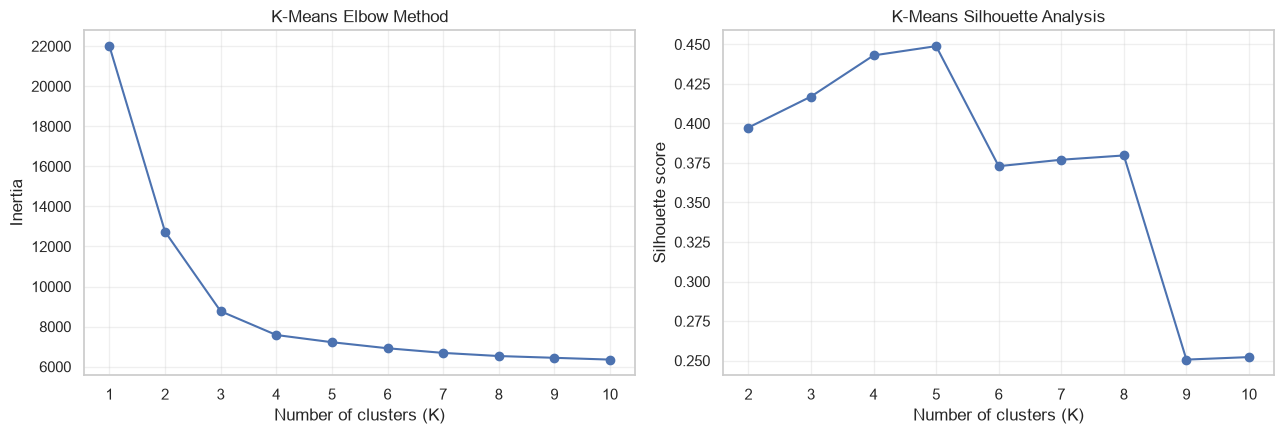

,n_clusters,inertia,silhouette_score
0,2,12737.604918,0.397407
1,3,8768.206521,0.417005
2,4,7581.829462,0.443020
3,5,7221.643979,0.448886
4,6,6919.616758,0.372964
5,7,6688.409382,0.377044
6,8,6531.406244,0.379752
7,9,6443.303076,0.250643
8,10,6353.814068,0.252229


K selected by maximum observed Silhouette score: 5

K-Means cluster sizes:


,records
cluster,
0,308
1,300
2,97
3,300
4,95


In [ ]:
k_values = list(range(2, min(11, len(X_scaled))))
inertia_values = []
silhouette_values = []

for k in range(1, min(11, len(X_scaled))):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)
    if k >= 2:
        silhouette_values.append(silhouette_score(X_scaled, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, len(inertia_values) + 1), inertia_values, marker='o')
axes[0].set_title('K-Means Elbow Method')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(range(1, len(inertia_values) + 1))
axes[0].grid(True, alpha=0.3)
axes[1].plot(k_values, silhouette_values, marker='o')
axes[1].set_title('K-Means Silhouette Analysis')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_xticks(k_values)
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / 'kmeans_elbow_and_silhouette.png', dpi=160, bbox_inches='tight')
plt.show()

k_selection = pd.DataFrame({
    'n_clusters': k_values,
    'inertia': inertia_values[1:],
    'silhouette_score': silhouette_values,
})
display(k_selection)
k_selection.to_csv(TABLE_DIR / 'kmeans_k_selection.csv', index=False)

selected_k = int(k_selection.loc[k_selection['silhouette_score'].idxmax(), 'n_clusters'])
print('K selected by maximum observed Silhouette score:', selected_k)

kmeans_model = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=20)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
print('\nK-Means cluster sizes:')
display(pd.Series(kmeans_labels, name='cluster').value_counts().sort_index().rename('records').to_frame())

## 6. Fit the clustering algorithms

In [ ]:
cluster_labels = {'K-Means': kmeans_labels}

agg_model = AgglomerativeClustering(n_clusters=selected_k, linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)
cluster_labels['Agglomerative'] = agg_labels

if HAS_BISECTING_KMEANS:
    divisive_model = BisectingKMeans(
        n_clusters=selected_k,
        random_state=RANDOM_STATE,
        n_init=10,
    )
    divisive_labels = divisive_model.fit_predict(X_scaled)
    cluster_labels['Bisecting K-Means'] = divisive_labels
else:
    divisive_labels = None
    print('BisectingKMeans is not available in this scikit-learn version; this model will be skipped.')

gmm_model = GaussianMixture(
    n_components=selected_k,
    covariance_type='full',
    random_state=RANDOM_STATE,
    reg_covar=1e-6,
    n_init=3,
)
gmm_labels = gmm_model.fit_predict(X_scaled)
cluster_labels['Gaussian Mixture'] = gmm_labels

print('Completed clustering models:', list(cluster_labels.keys()))

Completed clustering models: ['K-Means', 'Agglomerative', 'Bisecting K-Means', 'Gaussian Mixture']


## 7. DBSCAN: parameter tuning

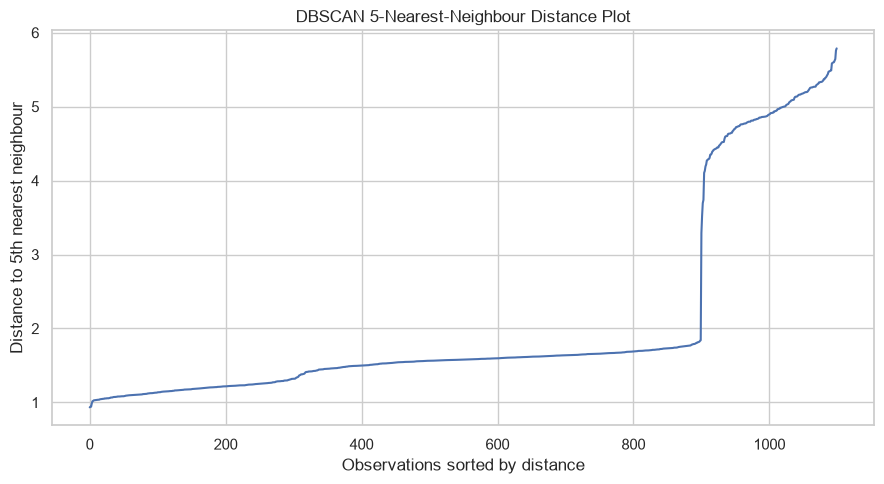

,eps,min_samples,clusters_excluding_noise,coverage_pct,noise_pct,silhouette_non_noise
0,5.335,5,1,100.000000,0.000000,NaN
1,5.643,10,1,100.000000,0.000000,NaN
2,5.808,15,1,100.000000,0.000000,NaN
3,5.418,10,1,99.909091,0.090909,NaN
4,5.557,15,1,99.909091,0.090909,NaN
5,5.162,5,1,99.272727,0.727273,NaN
6,5.227,15,1,99.090909,0.909091,NaN
7,5.119,10,1,98.636364,1.363636,NaN
8,4.860,5,1,96.000000,4.000000,NaN
9,1.802,10,4,81.818182,18.181818,0.481801


Selected DBSCAN eps=1.809, min_samples=15
Highest Silhouette score among configurations with at least 50% coverage and at least two clusters.
DBSCAN clusters excluding noise: 4
DBSCAN noise percentage: 19.0


In [ ]:
min_samples_values = [5, 10, 15]
quantiles = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.98]
dbscan_trials = []
dbscan_label_cache = {}

knn = NearestNeighbors(n_neighbors=5)
knn.fit(X_scaled)
distances_5, _ = knn.kneighbors(X_scaled)
k_distance = np.sort(distances_5[:, -1])
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_distance)
ax.set_title('DBSCAN 5-Nearest-Neighbour Distance Plot')
ax.set_xlabel('Observations sorted by distance')
ax.set_ylabel('Distance to 5th nearest neighbour')
fig.tight_layout()
fig.savefig(FIG_DIR / 'dbscan_k_distance.png', dpi=160, bbox_inches='tight')
plt.show()

for min_samples in min_samples_values:
    nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
    distances, _ = nn.kneighbors(X_scaled)
    kth_distances = distances[:, -1]
    eps_candidates = np.unique(np.round(np.quantile(kth_distances, quantiles), 3))

    for eps in eps_candidates:
        if eps <= 0:
            continue
        model = DBSCAN(eps=float(eps), min_samples=min_samples)
        labels = model.fit_predict(X_scaled)
        dbscan_label_cache[(float(eps), min_samples)] = labels

        non_noise = labels != -1
        n_clusters = len(set(labels[non_noise]))
        coverage = float(non_noise.mean())
        score = np.nan
        if n_clusters >= 2 and non_noise.sum() > n_clusters:
            try:
                score = silhouette_score(X_scaled[non_noise], labels[non_noise])
            except ValueError:
                pass

        dbscan_trials.append({
            'eps': float(eps),
            'min_samples': int(min_samples),
            'clusters_excluding_noise': int(n_clusters),
            'coverage_pct': coverage * 100,
            'noise_pct': (1 - coverage) * 100,
            'silhouette_non_noise': score,
        })

dbscan_tuning = pd.DataFrame(dbscan_trials).sort_values(
    ['coverage_pct', 'silhouette_non_noise'], ascending=[False, False]
).reset_index(drop=True)
display(dbscan_tuning)
dbscan_tuning.to_csv(TABLE_DIR / 'dbscan_tuning_results.csv', index=False)

valid_dbscan = dbscan_tuning[
    (dbscan_tuning['clusters_excluding_noise'] >= 2)
    & dbscan_tuning['silhouette_non_noise'].notna()
]
preferred_dbscan = valid_dbscan[valid_dbscan['coverage_pct'] >= 50]

if not preferred_dbscan.empty:
    chosen_dbscan_row = preferred_dbscan.sort_values('silhouette_non_noise', ascending=False).iloc[0]
    dbscan_selection_note = 'Highest Silhouette score among configurations with at least 50% coverage and at least two clusters.'
elif not valid_dbscan.empty:
    chosen_dbscan_row = valid_dbscan.sort_values(
        ['coverage_pct', 'silhouette_non_noise'], ascending=[False, False]
    ).iloc[0]
    dbscan_selection_note = 'No multi-cluster configuration reached 50% coverage; selected the valid configuration with the highest coverage.'
else:
    chosen_dbscan_row = dbscan_tuning.sort_values('coverage_pct', ascending=False).iloc[0]
    dbscan_selection_note = 'No tested configuration produced two non-noise clusters; selected the configuration with the highest coverage, but DBSCAN separation metrics are not meaningful.'

dbscan_eps = float(chosen_dbscan_row['eps'])
dbscan_min_samples = int(chosen_dbscan_row['min_samples'])
db_labels = dbscan_label_cache[(dbscan_eps, dbscan_min_samples)]
cluster_labels['DBSCAN'] = db_labels

print(f'Selected DBSCAN eps={dbscan_eps:.3f}, min_samples={dbscan_min_samples}')
print(dbscan_selection_note)
print('DBSCAN clusters excluding noise:', len(set(db_labels) - {-1}))
print('DBSCAN noise percentage:', round((db_labels == -1).mean() * 100, 2))

## 8. Evaluate all clustering models

,algorithm,clusters,coverage_pct,noise_pct,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,5,100.0,0.0,0.448886,2.309665,560.201385
1,Agglomerative,5,100.0,0.0,0.366715,1.727154,549.261687
2,Bisecting K-Means,5,100.0,0.0,0.445314,3.066251,537.183713
3,Gaussian Mixture,5,100.0,0.0,0.366715,1.727154,549.261687
4,DBSCAN,4,81.0,19.0,0.483176,1.129357,1796.999672


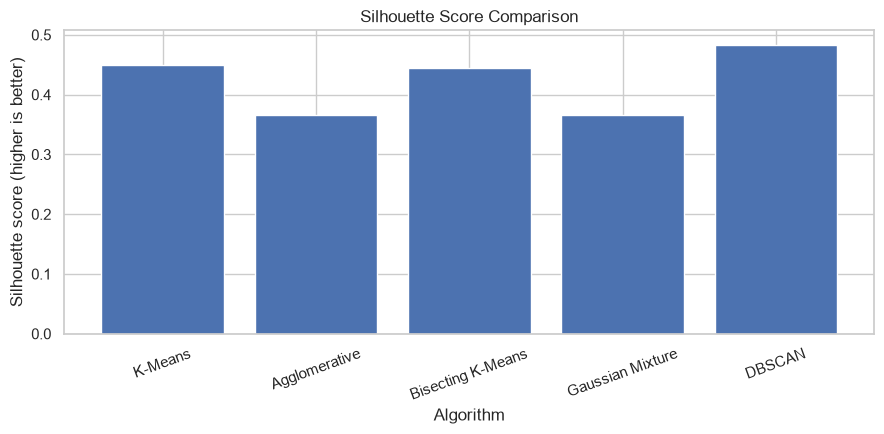

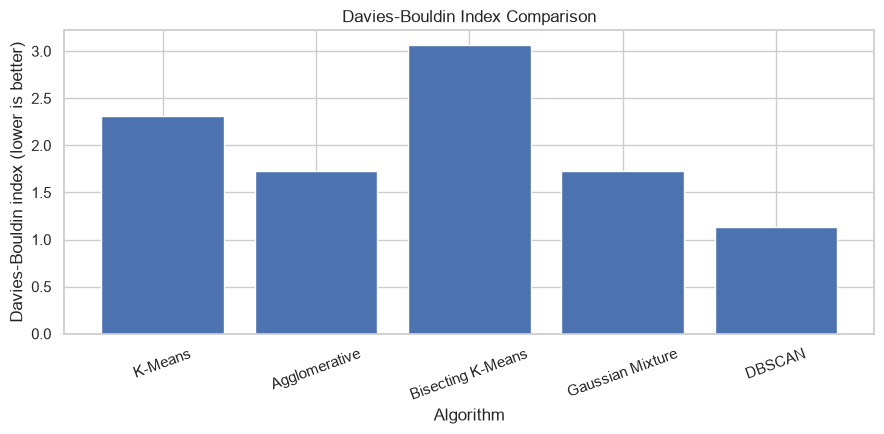

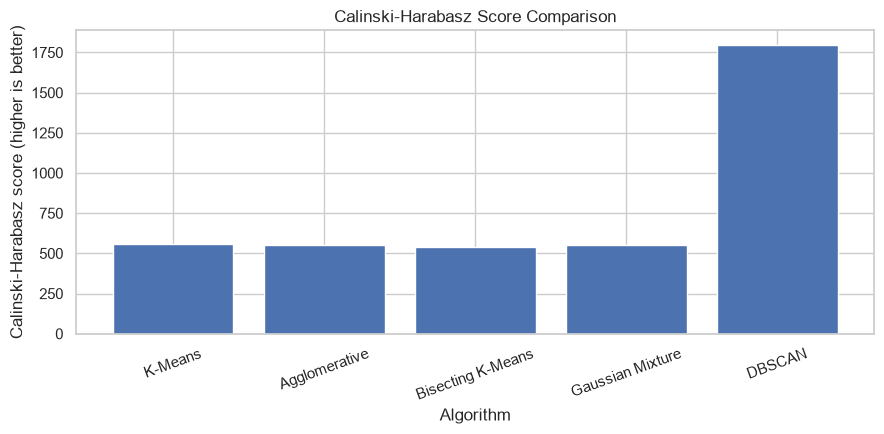

Interpret DBSCAN metrics together with its coverage and noise percentage.


In [ ]:
def clustering_metrics(labels, X_eval):
    """Return internal metrics; DBSCAN noise points (-1) are excluded."""
    labels = np.asarray(labels)
    mask = labels != -1
    labels_used = labels[mask]
    X_used = X_eval[mask]
    n_clusters = len(np.unique(labels_used))
    coverage = float(mask.mean())

    result = {
        'clusters': int(n_clusters),
        'coverage_pct': coverage * 100,
        'noise_pct': (1 - coverage) * 100,
        'silhouette': np.nan,
        'davies_bouldin': np.nan,
        'calinski_harabasz': np.nan,
    }
    if n_clusters >= 2 and len(labels_used) > n_clusters:
        result['silhouette'] = silhouette_score(X_used, labels_used)
        result['davies_bouldin'] = davies_bouldin_score(X_used, labels_used)
        result['calinski_harabasz'] = calinski_harabasz_score(X_used, labels_used)
    return result

metric_rows = []
for name, labels in cluster_labels.items():
    row = {'algorithm': name}
    row.update(clustering_metrics(labels, X_scaled))
    metric_rows.append(row)

model_comparison = pd.DataFrame(metric_rows)
display(model_comparison)
model_comparison.to_csv(TABLE_DIR / 'clustering_model_comparison.csv', index=False)

for metric, title, ylabel in [
    ('silhouette', 'Silhouette Score Comparison', 'Silhouette score (higher is better)'),
    ('davies_bouldin', 'Davies-Bouldin Index Comparison', 'Davies-Bouldin index (lower is better)'),
    ('calinski_harabasz', 'Calinski-Harabasz Score Comparison', 'Calinski-Harabasz score (higher is better)'),
]:
    plot_data = model_comparison.dropna(subset=[metric])
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(plot_data['algorithm'], plot_data[metric])
    ax.set_title(title)
    ax.set_xlabel('Algorithm')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=20)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{metric}_comparison.png', dpi=160, bbox_inches='tight')
    plt.show()

print('Interpret DBSCAN metrics together with its coverage and noise percentage.')

## 9. Cluster-size comparison

,algorithm,cluster_label,records,percentage
0,K-Means,0,308,28.000000
1,K-Means,1,300,27.272727
2,K-Means,2,97,8.818182
3,K-Means,3,300,27.272727
4,K-Means,4,95,8.636364
5,Agglomerative,0,200,18.181818
6,Agglomerative,1,154,14.000000
7,Agglomerative,2,300,27.272727
8,Agglomerative,3,300,27.272727
9,Agglomerative,4,146,13.272727


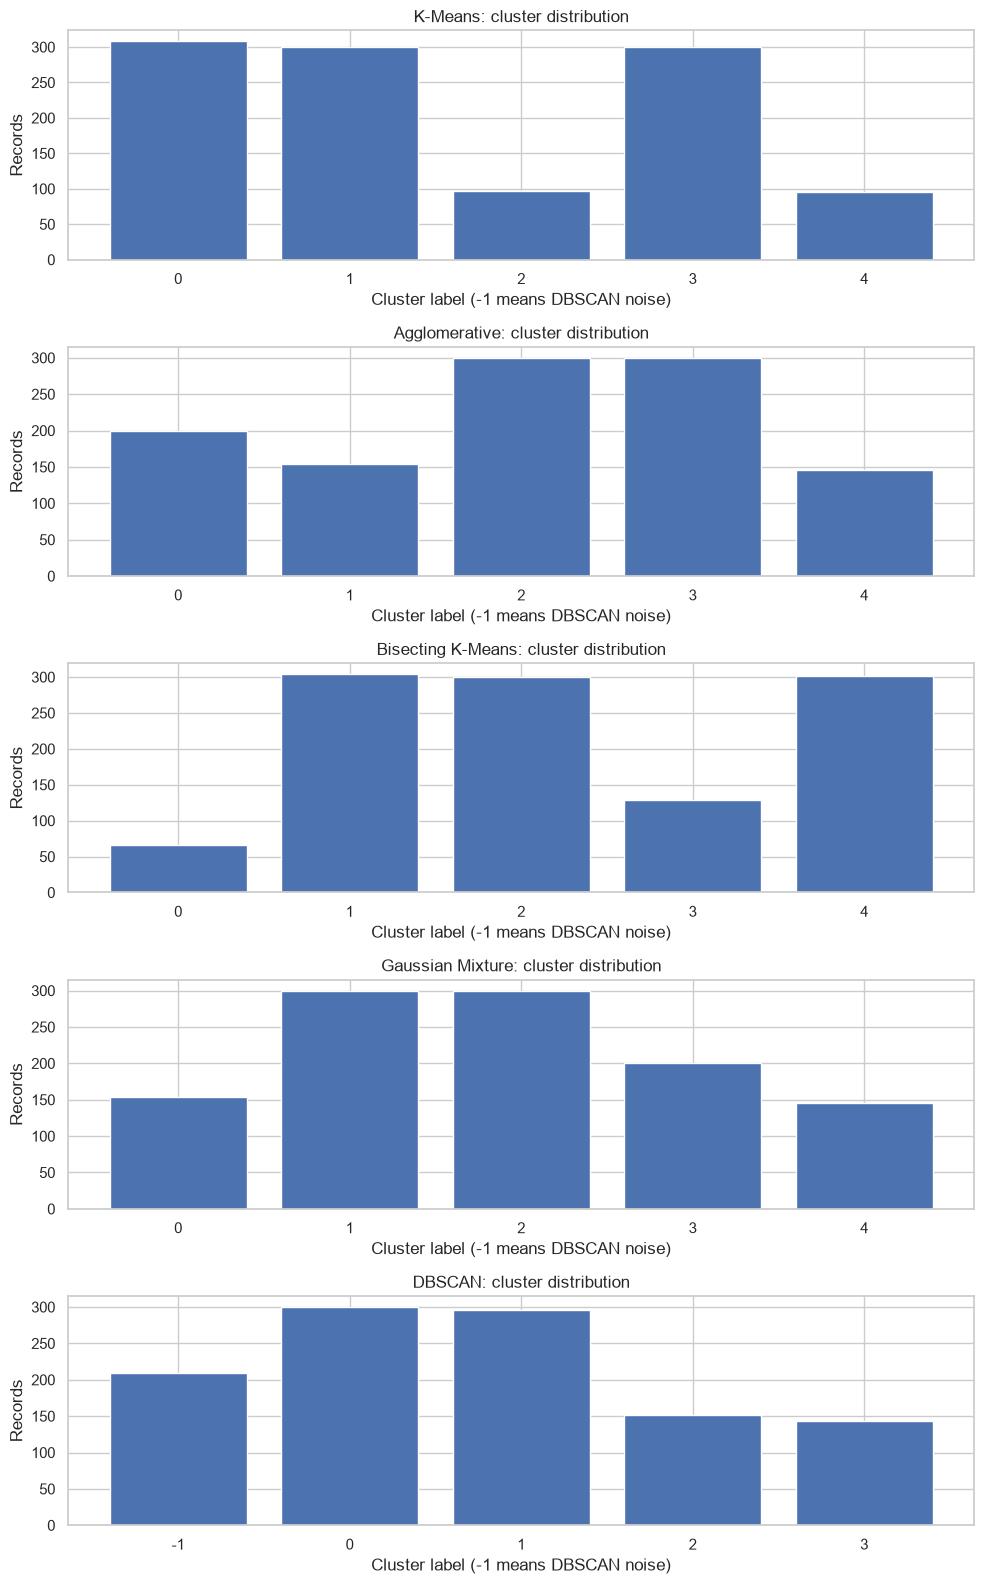

In [27]:
cluster_size_rows = []
for name, labels in cluster_labels.items():
    counts = pd.Series(labels).value_counts().sort_index()
    for cluster_id, count in counts.items():
        cluster_size_rows.append({
            'algorithm': name,
            'cluster_label': int(cluster_id),
            'records': int(count),
            'percentage': float(count / len(labels) * 100),
        })
cluster_sizes = pd.DataFrame(cluster_size_rows)
display(cluster_sizes)
cluster_sizes.to_csv(TABLE_DIR / 'cluster_sizes.csv', index=False)

fig, axes = plt.subplots(len(cluster_labels), 1, figsize=(10, 3.2 * len(cluster_labels)))
if len(cluster_labels) == 1:
    axes = [axes]
for ax, (name, labels) in zip(axes, cluster_labels.items()):
    counts = pd.Series(labels).value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(f'{name}: cluster distribution')
    ax.set_xlabel('Cluster label (-1 means DBSCAN noise)')
    ax.set_ylabel('Records')
fig.tight_layout()
fig.savefig(FIG_DIR / 'cluster_size_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## 10. PCA: dimensionality reduction and interpretation

Components needed for at least 95% explained variance: 16
Cumulative variance at that component: 0.9564


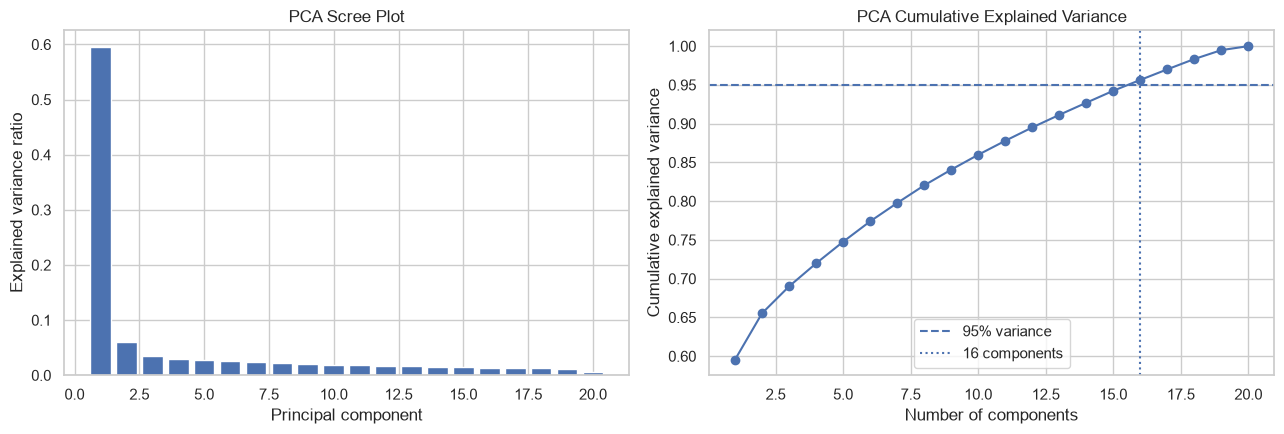

Variance explained by PC1 and PC2: 0.6554


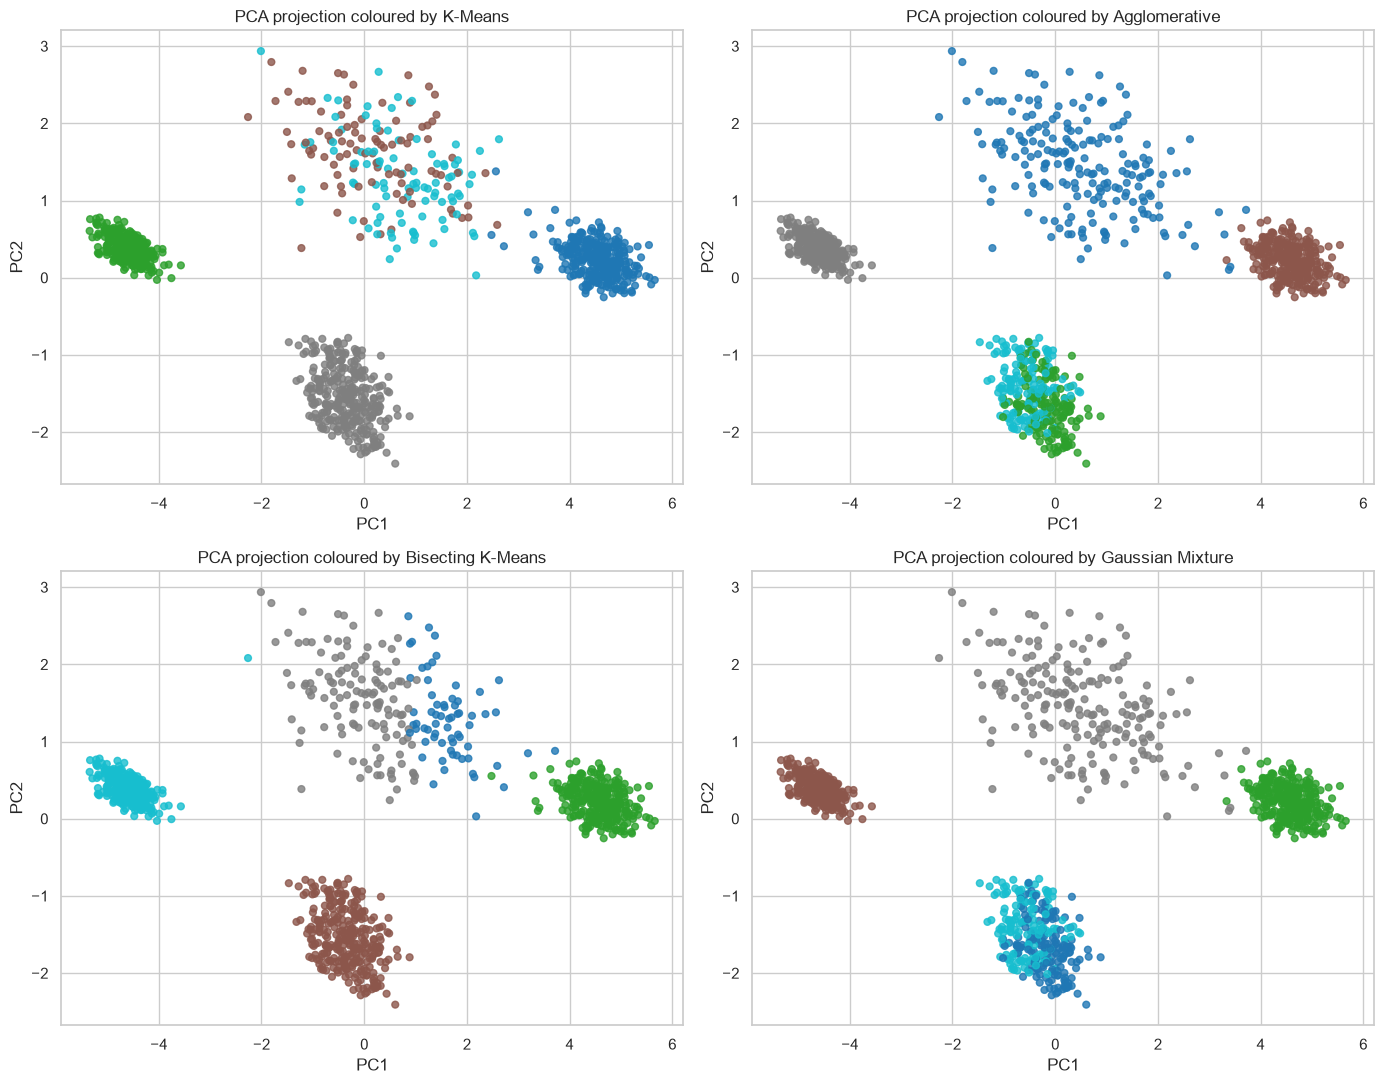

,PC1_loading,PC2_loading
future_career_concerns,0.247480,0.008331
anxiety_level,0.244210,-0.111202
bullying,0.242731,-0.089210
depression,0.242709,0.043185
self_esteem,-0.242044,-0.150199
sleep_quality,-0.240323,0.135088
teacher_student_relationship,-0.236666,-0.000421
academic_performance,-0.229500,0.135897
headache,0.229389,-0.013205
safety,-0.229310,0.084732


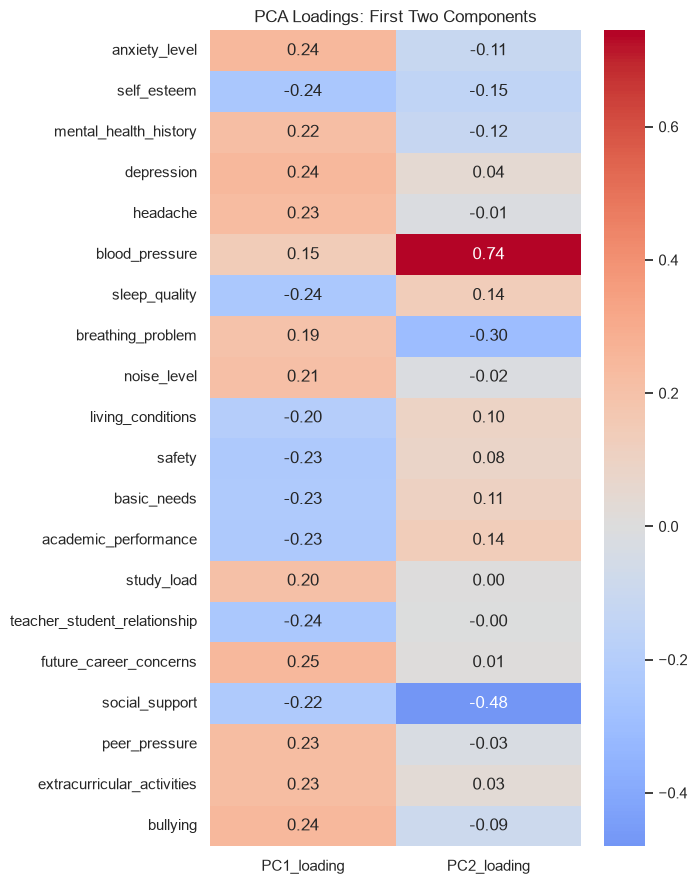

PCA-95 feature matrix shape: (1100, 16)


,feature_space,clusters,coverage_pct,noise_pct,silhouette,davies_bouldin,calinski_harabasz
0,Original standardized features,5,100.0,0.0,0.448886,2.309665,560.201385
1,PCA space (>=95% variance),5,100.0,0.0,0.472767,2.219904,637.882904


In [ ]:
pca_full = PCA(random_state=RANDOM_STATE)
X_pca_full = pca_full.fit_transform(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)

print('Components needed for at least 95% explained variance:', n_components_95)
print('Cumulative variance at that component:', round(cumulative_variance[n_components_95 - 1], 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, len(pca_full.explained_variance_ratio_) + 1),
            pca_full.explained_variance_ratio_)
axes[0].set_title('PCA Scree Plot')
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Explained variance ratio')
axes[1].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
axes[1].axhline(0.95, linestyle='--', label='95% variance')
axes[1].axvline(n_components_95, linestyle=':', label=f'{n_components_95} components')
axes[1].set_title('PCA Cumulative Explained Variance')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative explained variance')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'pca_explained_variance.png', dpi=160, bbox_inches='tight')
plt.show()

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled)
print('Variance explained by PC1 and PC2:', round(pca_2d.explained_variance_ratio_.sum(), 4))

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (name, labels) in zip(axes.flat, list(cluster_labels.items())[:4]):
    scatter = ax.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=labels, cmap='tab10', s=24, alpha=0.8)
    ax.set_title(f'PCA projection coloured by {name}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
for ax in axes.flat[len(cluster_labels):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'pca_cluster_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=feature_names,
    columns=['PC1_loading', 'PC2_loading'],
)
display(loadings.sort_values('PC1_loading', key=np.abs, ascending=False))
loadings.to_csv(TABLE_DIR / 'pca_loadings_pc1_pc2.csv')

fig, ax = plt.subplots(figsize=(7, 9))
sns.heatmap(loadings, cmap='coolwarm', center=0, annot=True, fmt='.2f', ax=ax)
ax.set_title('PCA Loadings: First Two Components')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pca_loadings_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()

pca_95 = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_pca_95 = pca_95.fit_transform(X_scaled)
print('PCA-95 feature matrix shape:', X_pca_95.shape)

kmeans_pca95 = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=20)
kmeans_pca95_labels = kmeans_pca95.fit_predict(X_pca_95)
pca95_metrics = clustering_metrics(kmeans_pca95_labels, X_pca_95)
original_metrics = clustering_metrics(kmeans_labels, X_scaled)
pca_space_comparison = pd.DataFrame([
    {'feature_space': 'Original standardized features', **original_metrics},
    {'feature_space': 'PCA space (>=95% variance)', **pca95_metrics},
])
display(pca_space_comparison)
pca_space_comparison.to_csv(TABLE_DIR / 'original_vs_pca95_kmeans.csv', index=False)

## 11. t-SNE visualization

t-SNE is used to visualize local neighbourhood structure in two dimensions. Its coordinates are not used as the primary space for evaluating clustering because the projection can alter global distances and apparent cluster sizes.


t-SNE embedding shape: (1100, 2)
t-SNE parameters: {'n_components': 2, 'perplexity': 30, 'learning_rate': 'auto', 'init': 'pca', 'random_state': 42, 'max_iter': 1000}
Final t-SNE KL divergence: 1.1568975448608398
All t-SNE coordinates finite: True


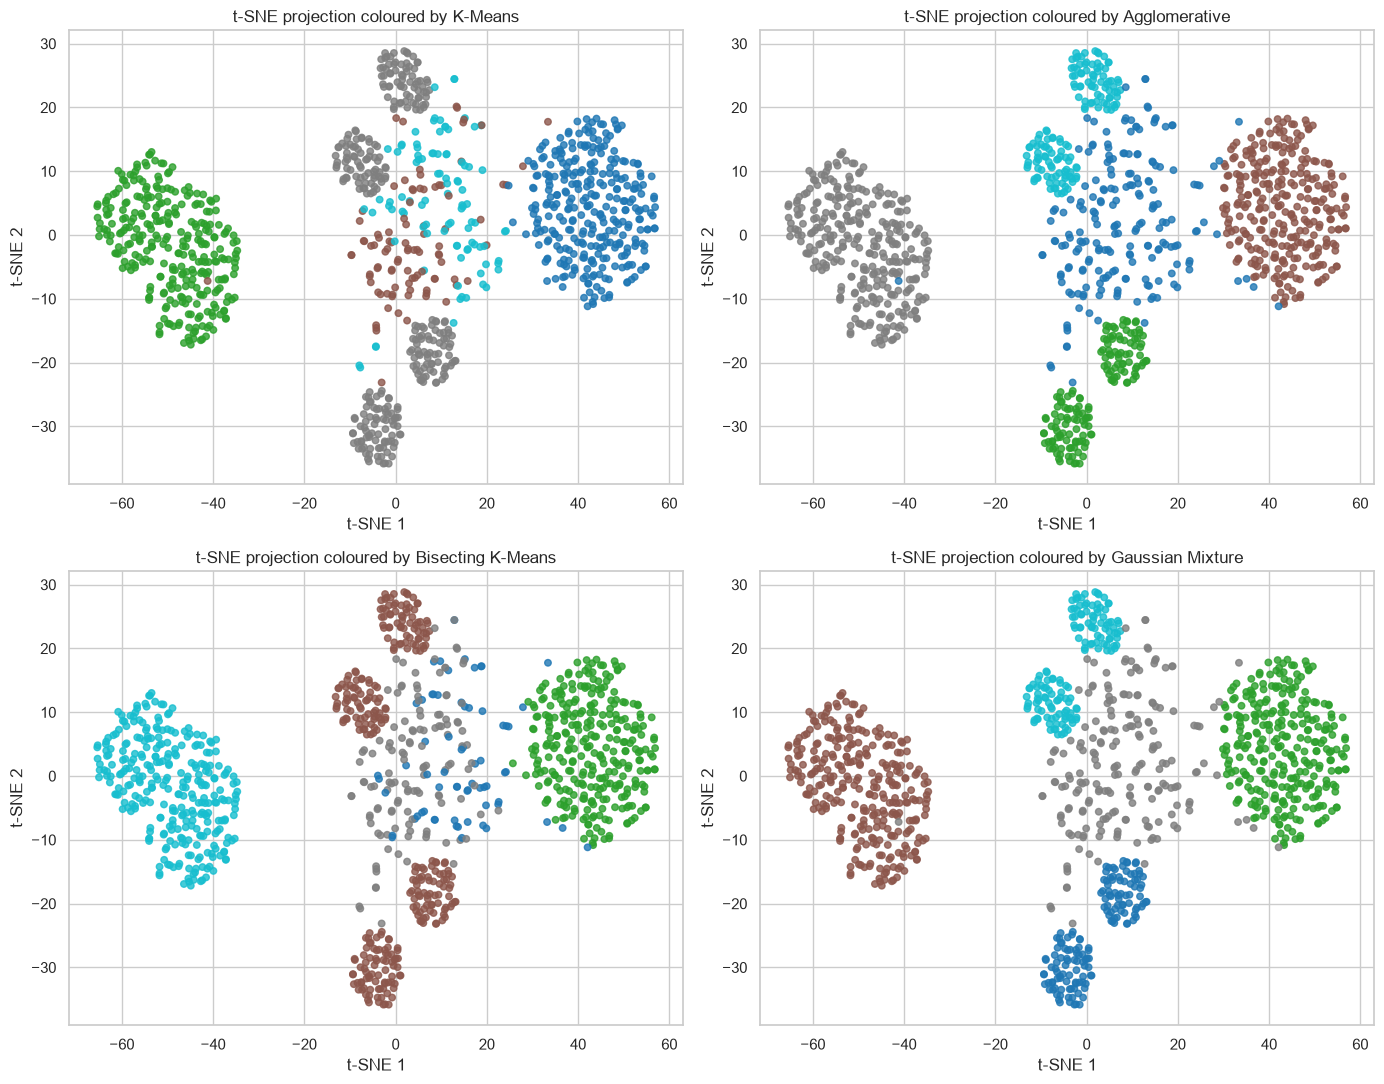

In [ ]:
tsne_parameters = inspect.signature(TSNE).parameters
iteration_argument = 'max_iter' if 'max_iter' in tsne_parameters else 'n_iter'
tsne_kwargs = {
    'n_components': 2,
    'perplexity': min(30, max(5, (len(X_scaled) - 1) // 3)),
    'learning_rate': 'auto',
    'init': 'pca',
    'random_state': RANDOM_STATE,
}
tsne_kwargs[iteration_argument] = 1000

tsne_model = TSNE(**tsne_kwargs)
X_tsne = tsne_model.fit_transform(X_scaled)
print('t-SNE embedding shape:', X_tsne.shape)
print('t-SNE parameters:', tsne_kwargs)
print('Final t-SNE KL divergence:', float(tsne_model.kl_divergence_))
print('All t-SNE coordinates finite:', bool(np.isfinite(X_tsne).all()))

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (name, labels) in zip(axes.flat, list(cluster_labels.items())[:4]):
    ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap='tab10', s=22, alpha=0.8)
    ax.set_title(f't-SNE projection coloured by {name}')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
for ax in axes.flat[len(cluster_labels):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'tsne_cluster_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

pd.DataFrame(X_tsne, columns=['tsne_1', 'tsne_2']).to_csv(
    TABLE_DIR / 'tsne_embedding.csv', index=False
)

## 12. SNE visualization

SNE uses conditional Gaussian probabilities in both the original feature space and the two-dimensional embedding. The objective minimizes the sum of row-wise Kullback–Leibler divergences. Unlike t-SNE, SNE uses a Gaussian distribution in the lower-dimensional space.

The calculation is performed on a deterministic sample of up to 800 records to limit runtime. The same sampled records are used in the cluster-coloured plot. Optimizer convergence, iteration count, objective value, and gradient norm are recorded.


Original SNE completed.
Converged: True
Optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Iterations: 106
Function evaluations: 111
Final KL objective: 1168.6407142409091
Final gradient norm: 0.0013961003185111156
Records used for SNE: 800
All SNE coordinates finite: True


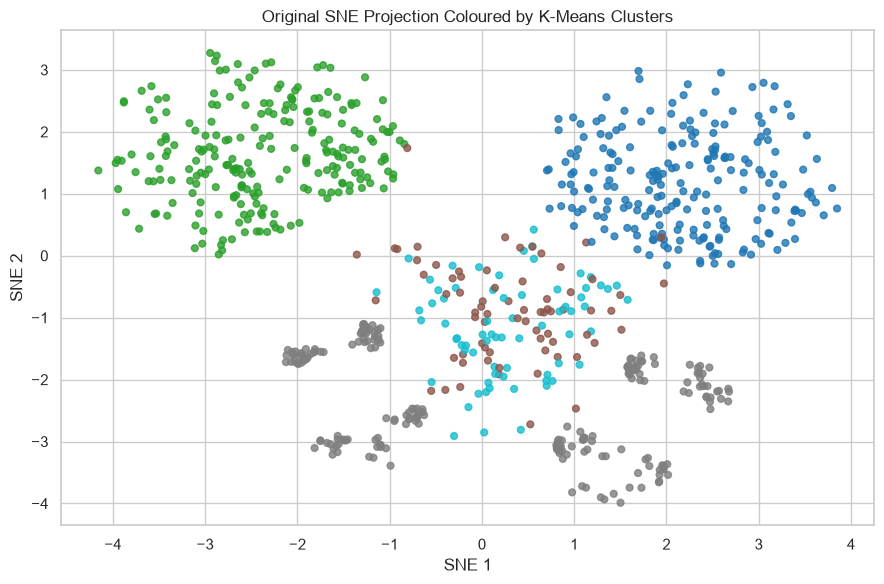

,perplexity,sample_size,converged,optimizer_message,iterations,function_evaluations,final_kl_objective,gradient_norm
0,30.0,800,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,106,111,1168.640714,0.001396


In [ ]:
from scipy.special import logsumexp


def _entropy_and_probabilities(distances, beta):
    """Return entropy and conditional Gaussian probabilities for one row."""
    log_weights = -beta * distances
    log_normalizer = logsumexp(log_weights)
    probabilities = np.exp(log_weights - log_normalizer)
    entropy = log_normalizer + beta * np.sum(distances * probabilities)
    return entropy, probabilities


def compute_sne_conditional_probabilities(
    X_input, perplexity=30.0, tolerance=1e-5, max_tries=60
):
    """Compute original-SNE high-dimensional conditional probabilities p(j|i)."""
    n_samples = X_input.shape[0]
    if not 1 < perplexity < n_samples:
        raise ValueError('perplexity must be greater than 1 and smaller than the sample count')

    distances = pairwise_distances(X_input, metric='euclidean', squared=True)
    conditional = np.zeros((n_samples, n_samples), dtype=float)
    target_entropy = np.log(perplexity)

    for i in range(n_samples):
        mask = np.ones(n_samples, dtype=bool)
        mask[i] = False
        row_distances = distances[i, mask]

        beta = 1.0
        beta_min = 0.0
        beta_max = np.inf

        for _ in range(max_tries):
            entropy, row_probabilities = _entropy_and_probabilities(row_distances, beta)
            difference = entropy - target_entropy
            if abs(difference) <= tolerance:
                break

            if difference > 0:
                beta_min = beta
                beta = beta * 2.0 if np.isinf(beta_max) else (beta + beta_max) / 2.0
            else:
                beta_max = beta
                beta = beta / 2.0 if beta_min == 0.0 else (beta + beta_min) / 2.0

        conditional[i, mask] = row_probabilities

    return conditional


def original_sne_objective(flat_embedding, conditional_probabilities, n_samples, n_components=2):
    """Original SNE KL objective and analytic gradient for Gaussian q(j|i)."""
    embedding = flat_embedding.reshape(n_samples, n_components)

    distances = pairwise_distances(embedding, metric='euclidean', squared=True)
    np.fill_diagonal(distances, np.inf)

    log_q = -distances
    log_q -= logsumexp(log_q, axis=1, keepdims=True)
    q = np.exp(log_q)

    positive = conditional_probabilities > 0
    cost = np.sum(
        conditional_probabilities[positive]
        * (np.log(conditional_probabilities[positive]) - log_q[positive])
    )

    differences = embedding[:, None, :] - embedding[None, :, :]
    residual = (conditional_probabilities - q) + (conditional_probabilities.T - q.T)
    gradient = 2.0 * np.sum(residual[:, :, None] * differences, axis=1)

    return float(cost), gradient.ravel()


SNE_MAX_SAMPLES = min(800, len(X_scaled))
rng = np.random.default_rng(RANDOM_STATE)
sne_indices = np.sort(rng.choice(len(X_scaled), size=SNE_MAX_SAMPLES, replace=False))
X_sne_input = X_scaled[sne_indices]
sne_labels_for_plot = kmeans_labels[sne_indices]

sne_perplexity = min(30.0, max(5.0, (SNE_MAX_SAMPLES - 1) / 3.0))
P_sne_conditional = compute_sne_conditional_probabilities(
    X_sne_input,
    perplexity=sne_perplexity
)

sne_initial = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_sne_input)
sne_initial = (sne_initial - sne_initial.mean(axis=0)) / (sne_initial.std(axis=0) + 1e-12)

sne_result = minimize(
    original_sne_objective,
    sne_initial.ravel(),
    args=(P_sne_conditional, SNE_MAX_SAMPLES, 2),
    method='L-BFGS-B',
    jac=True,
    options={
        'maxiter': 1200,
        'ftol': 1e-9,
        'gtol': 1e-5,
        'maxls': 50,
        'maxcor': 10,
    },
)

X_sne = sne_result.x.reshape(SNE_MAX_SAMPLES, 2)
sne_gradient_norm = float(np.linalg.norm(sne_result.jac))
print('Original SNE completed.')
print('Converged:', bool(sne_result.success))
print('Optimizer message:', sne_result.message)
print('Iterations:', int(sne_result.nit))
print('Function evaluations:', int(sne_result.nfev))
print('Final KL objective:', float(sne_result.fun))
print('Final gradient norm:', sne_gradient_norm)
print('Records used for SNE:', SNE_MAX_SAMPLES)
print('All SNE coordinates finite:', bool(np.isfinite(X_sne).all()))

if not sne_result.success:
    warnings.warn(
        'Original SNE optimizer did not report convergence. Treat its embedding as exploratory '
        'and report the optimizer message and gradient norm; do not describe it as converged.'
    )

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    X_sne[:, 0], X_sne[:, 1],
    c=sne_labels_for_plot,
    cmap='tab10', s=24, alpha=0.8,
)
ax.set_title('Original SNE Projection Coloured by K-Means Clusters')
ax.set_xlabel('SNE 1')
ax.set_ylabel('SNE 2')
fig.tight_layout()
fig.savefig(FIG_DIR / 'original_sne_kmeans.png', dpi=160, bbox_inches='tight')
plt.show()

sne_embedding_table = pd.DataFrame({
    'original_row_index': sne_indices,
    'sne_1': X_sne[:, 0],
    'sne_2': X_sne[:, 1],
    'kmeans_cluster': sne_labels_for_plot,
})
sne_embedding_table.to_csv(TABLE_DIR / 'original_sne_embedding.csv', index=False)

sne_diagnostics = pd.DataFrame([{
    'perplexity': sne_perplexity,
    'sample_size': SNE_MAX_SAMPLES,
    'converged': bool(sne_result.success),
    'optimizer_message': str(sne_result.message),
    'iterations': int(sne_result.nit),
    'function_evaluations': int(sne_result.nfev),
    'final_kl_objective': float(sne_result.fun),
    'gradient_norm': sne_gradient_norm,
}])
display(sne_diagnostics)
sne_diagnostics.to_csv(TABLE_DIR / 'original_sne_diagnostics.csv', index=False)


## 13. Cluster profiles and post-hoc validation

K-Means cluster feature means:


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying
kmeans_cluster,,,,,,,,,,,,,,,,,,,,
0,17.993506,7.844156,0.996753,21.357143,3.925325,3.0,1.009740,3.938312,4.000000,1.525974,1.548701,1.529221,1.487013,3.964286,1.477273,4.477273,0.990260,4.487013,4.425325,4.435065
1,4.190000,27.430000,0.000000,4.096667,1.000000,2.0,4.486667,1.513333,1.470000,3.526667,4.496667,4.520000,4.506667,1.490000,4.466667,1.000000,3.000000,1.523333,1.490000,1.000000
2,9.525773,16.288660,0.443299,14.567010,2.783505,3.0,2.804124,1.938144,2.731959,3.814433,2.711340,2.175258,2.536082,3.010309,2.195876,2.381443,0.587629,2.371134,2.154639,2.237113
3,11.410000,19.980000,0.513333,11.640000,2.483333,1.0,2.456667,3.026667,2.523333,2.483333,2.476667,2.513333,2.473333,2.486667,2.483333,2.460000,2.526667,2.466667,2.483333,2.560000
4,10.778947,14.063158,0.400000,11.568421,2.473684,3.0,2.736842,2.800000,2.305263,1.336842,1.884211,2.715789,2.652632,1.873684,1.684211,2.800000,0.526316,2.094737,2.947368,2.400000


K-Means cluster feature medians:


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying
kmeans_cluster,,,,,,,,,,,,,,,,,,,,
0,18.0,8.0,1.0,22.0,4.0,3.0,1.0,4.0,4.0,2.0,2.0,2.0,1.0,4.0,1.0,5.0,1.0,5.0,4.0,4.0
1,4.0,27.0,0.0,4.0,1.0,2.0,4.0,2.0,1.0,4.0,4.0,5.0,5.0,1.0,4.0,1.0,3.0,2.0,1.0,1.0
2,8.0,18.0,0.0,14.0,3.0,3.0,3.0,2.0,3.0,4.0,3.0,2.0,2.0,3.0,2.0,2.0,1.0,2.0,2.0,2.0
3,11.0,20.0,1.0,12.0,2.0,1.0,2.0,4.0,3.0,2.0,2.0,3.0,2.0,2.0,2.0,2.0,3.0,2.0,2.0,3.0
4,11.0,13.0,0.0,10.0,3.0,3.0,3.0,3.0,2.0,1.0,2.0,3.0,2.0,1.0,2.0,3.0,1.0,2.0,3.0,2.0


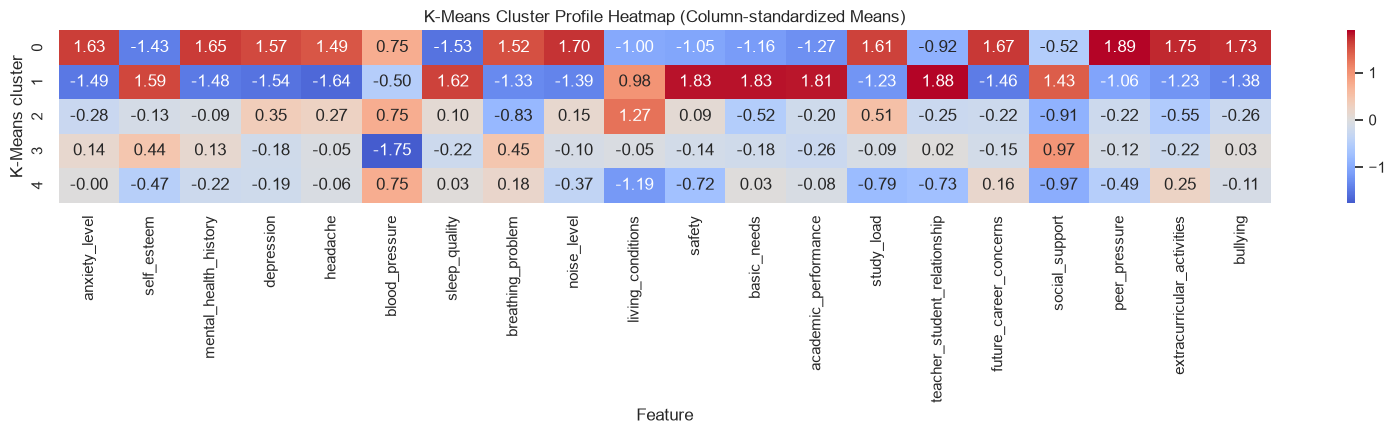

Post-hoc cross-tabulation (counts):


encoded_stress_level,0,1,2
kmeans_cluster,,,
0,1,5,302
1,300,0,0
2,33,27,37
3,0,300,0
4,39,26,30


Post-hoc row percentages:


encoded_stress_level,0,1,2
kmeans_cluster,,,
0,0.32,1.62,98.05
1,100.00,0.00,0.00
2,34.02,27.84,38.14
3,0.00,100.00,0.00
4,41.05,27.37,31.58


Post-hoc external validation (not used for training or model selection):


,algorithm,adjusted_rand_index_vs_stress_level,normalized_mutual_info_vs_stress_level
0,K-Means,0.716580,0.679221
1,Agglomerative,0.609632,0.676251
2,Bisecting K-Means,0.720849,0.691389
3,Gaussian Mixture,0.609632,0.676251
4,DBSCAN,0.598987,0.669223


In [ ]:
profile_data = X_numeric.copy()
profile_data['kmeans_cluster'] = kmeans_labels
cluster_profile_mean = profile_data.groupby('kmeans_cluster').mean()
cluster_profile_median = profile_data.groupby('kmeans_cluster').median()

print('K-Means cluster feature means:')
display(cluster_profile_mean)
print('K-Means cluster feature medians:')
display(cluster_profile_median)
cluster_profile_mean.to_csv(TABLE_DIR / 'kmeans_cluster_profile_means.csv')
cluster_profile_median.to_csv(TABLE_DIR / 'kmeans_cluster_profile_medians.csv')

profile_z = (cluster_profile_mean - cluster_profile_mean.mean()) / cluster_profile_mean.std(ddof=0).replace(0, 1)
fig, ax = plt.subplots(figsize=(16, 4.5))
sns.heatmap(profile_z, cmap='coolwarm', center=0, annot=True, fmt='.2f', ax=ax)
ax.set_title('K-Means Cluster Profile Heatmap (Column-standardized Means)')
ax.set_xlabel('Feature')
ax.set_ylabel('K-Means cluster')
fig.tight_layout()
fig.savefig(FIG_DIR / 'kmeans_cluster_profile_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()

posthoc_table = pd.crosstab(
    pd.Series(kmeans_labels, name='kmeans_cluster'),
    y.rename('encoded_stress_level'),
)
posthoc_row_pct = posthoc_table.div(posthoc_table.sum(axis=1), axis=0) * 100
print('Post-hoc cross-tabulation (counts):')
display(posthoc_table)
print('Post-hoc row percentages:')
display(posthoc_row_pct.round(2))
posthoc_table.to_csv(TABLE_DIR / 'kmeans_cluster_vs_stress_level_counts.csv')
posthoc_row_pct.to_csv(TABLE_DIR / 'kmeans_cluster_vs_stress_level_row_pct.csv')

external_rows = []
for name, labels in cluster_labels.items():
    if len(np.unique(labels)) >= 2:
        external_rows.append({
            'algorithm': name,
            'adjusted_rand_index_vs_stress_level': adjusted_rand_score(y, labels),
            'normalized_mutual_info_vs_stress_level': normalized_mutual_info_score(y, labels),
        })
external_validation = pd.DataFrame(external_rows)
print('Post-hoc external validation (not used for training or model selection):')
display(external_validation)
external_validation.to_csv(TABLE_DIR / 'posthoc_external_validation.csv', index=False)

## 14. Compare clustering algorithms in a single PCA visualization

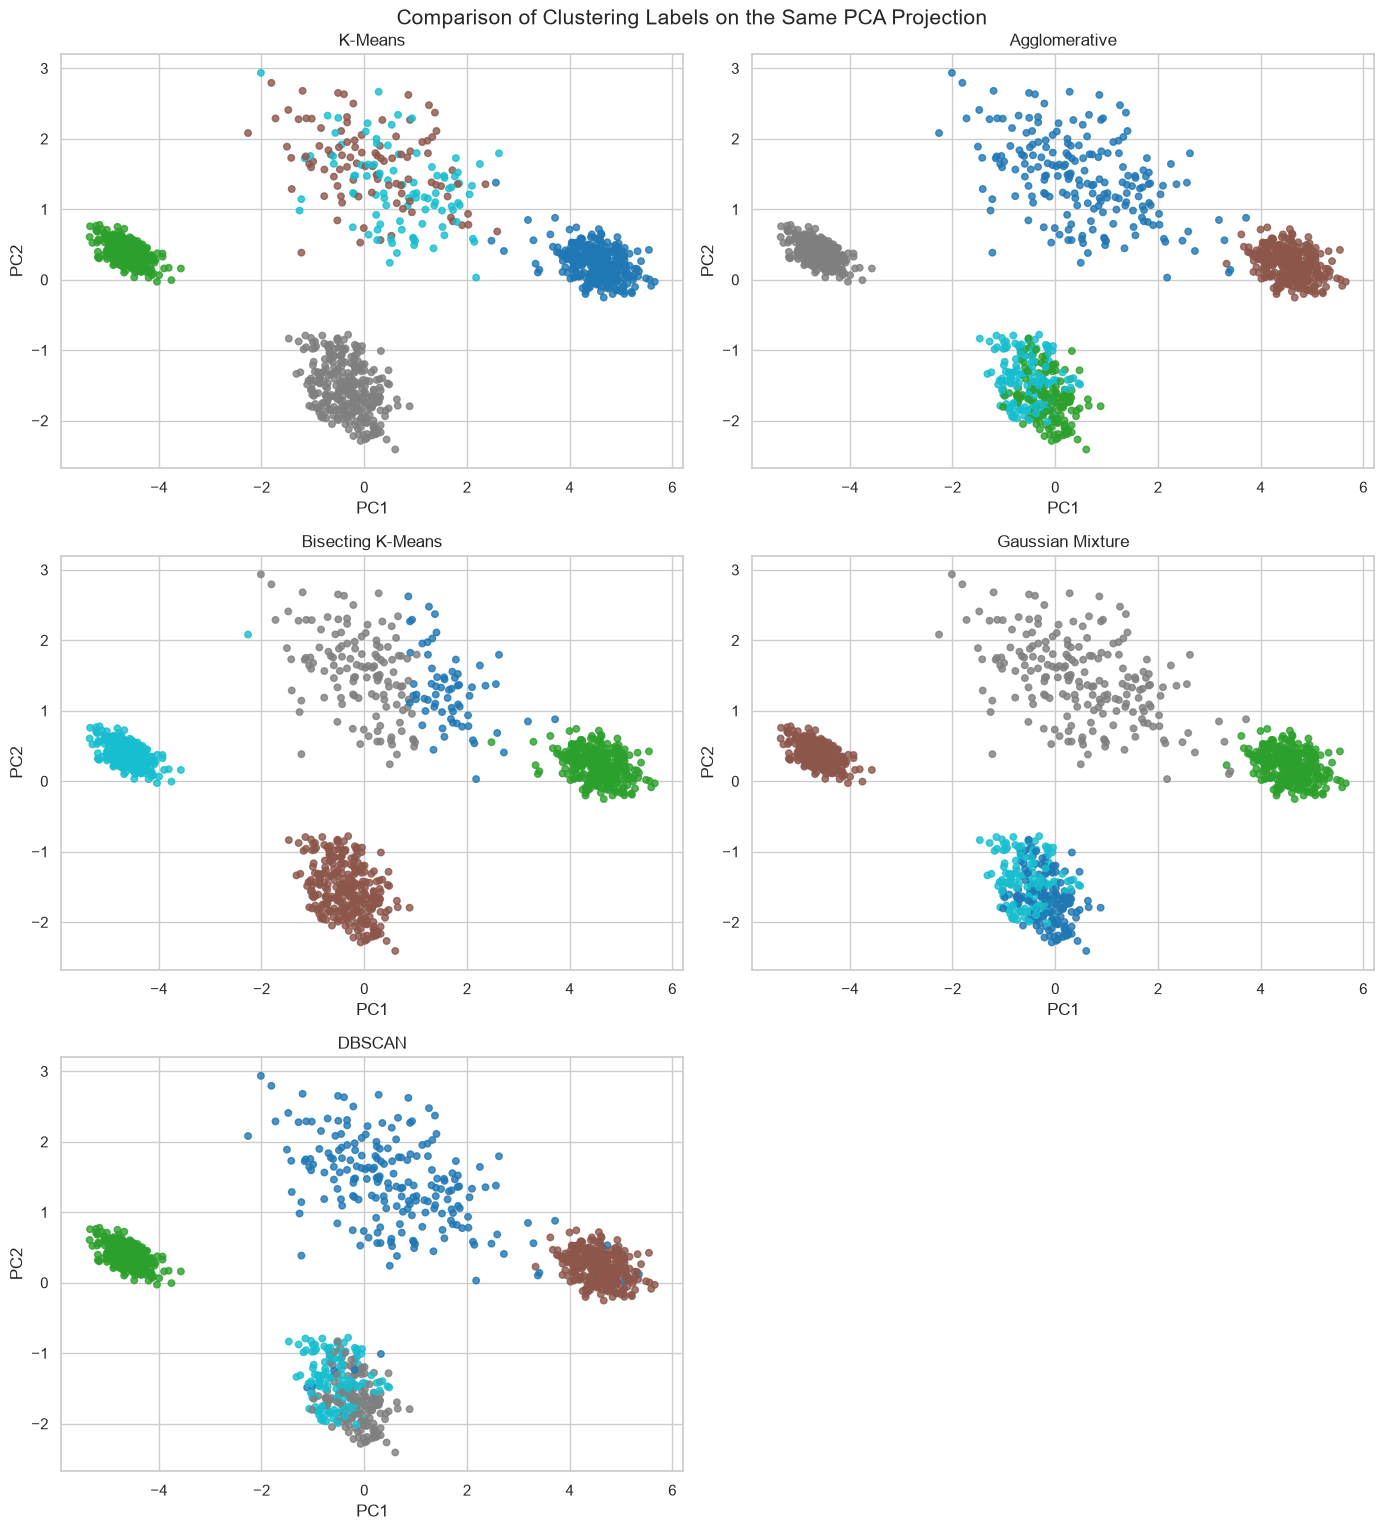

In [32]:
plot_items = list(cluster_labels.items())
n_plots = len(plot_items)
n_cols = 2
n_rows = math.ceil(n_plots / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5.2 * n_rows))
axes = np.array(axes).reshape(-1)
for ax, (name, labels) in zip(axes, plot_items):
    ax.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=labels, cmap='tab10', s=22, alpha=0.8)
    ax.set_title(name)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
for ax in axes[n_plots:]:
    ax.set_visible(False)
fig.suptitle('Comparison of Clustering Labels on the Same PCA Projection', fontsize=15)
fig.tight_layout()
fig.savefig(FIG_DIR / 'all_algorithms_pca_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## 15. Optional: K-Means stability across random seeds

In [ ]:
stability_labels = []
for seed in range(10):
    model = KMeans(n_clusters=selected_k, random_state=seed, n_init=10)
    stability_labels.append(model.fit_predict(X_scaled))

stability_scores = []
for i in range(len(stability_labels)):
    for j in range(i + 1, len(stability_labels)):
        stability_scores.append(adjusted_rand_score(stability_labels[i], stability_labels[j]))

print('Mean pairwise K-Means stability ARI:', round(float(np.mean(stability_scores)), 4))
print('Minimum pairwise K-Means stability ARI:', round(float(np.min(stability_scores)), 4))
pd.DataFrame({'pairwise_ari': stability_scores}).to_csv(
    TABLE_DIR / 'kmeans_stability_pairwise_ari.csv', index=False
)

Mean pairwise K-Means stability ARI: 0.9383
Minimum pairwise K-Means stability ARI: 0.8469


## 16. Save final results and project artefacts

In [ ]:
assignments = pd.DataFrame(index=df.index)
assignments['original_stress_level_posthoc_only'] = y
for name, labels in cluster_labels.items():
    safe_name = name.lower().replace(' ', '_').replace('-', '_')
    assignments[f'{safe_name}_cluster'] = labels
assignments['pca_1'] = X_pca_2d[:, 0]
assignments['pca_2'] = X_pca_2d[:, 1]
assignments['tsne_1'] = X_tsne[:, 0]
assignments['tsne_2'] = X_tsne[:, 1]
assignments.to_csv(OUTPUT_DIR / 'final_cluster_assignments.csv', index=False)

model_comparison.to_csv(OUTPUT_DIR / 'final_algorithm_comparison.csv', index=False)
cluster_sizes.to_csv(OUTPUT_DIR / 'final_cluster_sizes.csv', index=False)

metadata = {
    'dataset_file': str(DATA_PATH),
    'dataset_shape': [int(df.shape[0]), int(df.shape[1])],
    'predictor_count': int(X_scaled.shape[1]),
    'target_excluded_from_model_inputs': TARGET,
    'selected_k': int(selected_k),
    'dbscan_eps': float(dbscan_eps),
    'dbscan_min_samples': int(dbscan_min_samples),
    'dbscan_selection_note': dbscan_selection_note,
    'algorithms': list(cluster_labels.keys()),
    'pca_components_for_95_percent_variance': int(n_components_95),
    'tsne_parameters': {k: (int(v) if isinstance(v, np.integer) else v) for k, v in tsne_kwargs.items()},
    'original_sne_sample_size': int(SNE_MAX_SAMPLES),
    'original_sne_converged': bool(sne_result.success),
    'original_sne_optimizer_message': str(sne_result.message),
    'original_sne_final_kl_objective': float(sne_result.fun),
    'original_sne_gradient_norm': float(np.linalg.norm(sne_result.jac)),
    'random_state': RANDOM_STATE,
}
with open(OUTPUT_DIR / 'model_metadata.json', 'w', encoding='utf-8') as file:
    json.dump(metadata, file, indent=2, default=str)

print('Saved outputs to:', OUTPUT_DIR.resolve())
print('Figures:', FIG_DIR.resolve())
print('Tables:', TABLE_DIR.resolve())
print('Assignments:', (OUTPUT_DIR / 'final_cluster_assignments.csv').resolve())
print('Metadata:', (OUTPUT_DIR / 'model_metadata.json').resolve())

print('\nFinal internal metric comparison:')
display(model_comparison)

print('\nFinal external validation (post-hoc only):')
display(external_validation)

Saved outputs to: C:\USLA PROJECT\student-stress-unsupervised-learning-main\outputs_student_stress
Figures: C:\USLA PROJECT\student-stress-unsupervised-learning-main\outputs_student_stress\figures
Tables: C:\USLA PROJECT\student-stress-unsupervised-learning-main\outputs_student_stress\tables
Assignments: C:\USLA PROJECT\student-stress-unsupervised-learning-main\outputs_student_stress\final_cluster_assignments.csv
Metadata: C:\USLA PROJECT\student-stress-unsupervised-learning-main\outputs_student_stress\model_metadata.json

Final internal metric comparison:


,algorithm,clusters,coverage_pct,noise_pct,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,5,100.0,0.0,0.448886,2.309665,560.201385
1,Agglomerative,5,100.0,0.0,0.366715,1.727154,549.261687
2,Bisecting K-Means,5,100.0,0.0,0.445314,3.066251,537.183713
3,Gaussian Mixture,5,100.0,0.0,0.366715,1.727154,549.261687
4,DBSCAN,4,81.0,19.0,0.483176,1.129357,1796.999672



Final external validation (post-hoc only):


,algorithm,adjusted_rand_index_vs_stress_level,normalized_mutual_info_vs_stress_level
0,K-Means,0.716580,0.679221
1,Agglomerative,0.609632,0.676251
2,Bisecting K-Means,0.720849,0.691389
3,Gaussian Mixture,0.609632,0.676251
4,DBSCAN,0.598987,0.669223


## 17. References and interpretation notes

Cluster numbers are arbitrary identifiers and do not represent stress categories by themselves. Confirm the meanings of `stress_level` values 0, 1, and 2 from the dataset documentation before assigning names to them.

Silhouette, Davies–Bouldin, and Calinski–Harabasz scores describe cluster geometry; they do not establish psychological or clinical validity. t-SNE and SNE plots are visual summaries and should not be treated as proof of global separation. SNE uses a sample of up to 800 records, which should be stated when reporting its results.
